# 05_o3 — Sequential feature selection (Medellín, o3 target)

Mirrors Bogotá's LOYO-CV neural-net forward-selection methodology exactly (see
`Scripts/colombia/bogota/06_o3_feature_selection.ipynb`). Applies the same
lesson learned from Bogotá from the start: the "no-lag" run excludes calendar terms
(`doy_sin`/`doy_cos`/`month_sin`/`month_cos`) as well as `o3_lag1`, rather than
re-discovering the greedy-SFS calendar-shortcut issue the slow way.

**No causal exclusions needed** here (unlike PM2.5) -- PM2.5/PMC/NO2/NO have no
definitional-subset relationship with O3 (NOx chemistry and aerosol-radiation feedback
are textbook causal mechanisms, not leakage).


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

DATA_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "medellin"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "medellin" / "figures"

df = pd.read_parquet(DATA_DIR / "medellin_o3_master_dataset.parquet")
df = df.dropna(subset=['o3']).reset_index(drop=True)
df['year'] = df['date'].dt.year
print(df.shape)
df['year'].value_counts().sort_index()


(1423, 262)


year
2019    362
2020    365
2021    362
2022    334
Name: count, dtype: int64

In [2]:
EXCLUDE = {'date', 'o3', 'year'}

RAW_SUBCOMPONENT_EXCLUDE = {c for c in df.columns if any(
    c == base or c.startswith(base + '_lag')
    for base in ['pm25_hourmean', 'pm25_antioquia', 'pm10_hourmean', 'pm10_antioquia',
                 'no2_hourmean', 'no2_antioquia',
                 'wind_speed_antioquia', 'wind_speed_hybrid_station_era5', 'wind_speed_era5', 'wind_speed_station',
                 'wind_dir_antioquia', 'wind_dir_hybrid_station_era5', 'wind_dir_era5', 'wind_dir_station',
                 'temp_2m_era5', 'temp_2m_station', 'temp_2m_hybrid_station_era5',
                 'rh_2m_era5', 'rh_2m_station', 'rh_2m_hybrid_station_era5']
)}
EXCLUDE |= RAW_SUBCOMPONENT_EXCLUDE
print(f"Excluding raw/intermediate sub-components (leakage-adjacent, redundant with the "
      f"final calibrated column): {sorted(RAW_SUBCOMPONENT_EXCLUDE)}")

ALL_CANDIDATES = [c for c in df.columns if c not in EXCLUDE]
print(f"{len(ALL_CANDIDATES)} total candidate columns")

MIN_COVERAGE = 0.70
coverage = df[ALL_CANDIDATES].notna().mean()
CANDIDATES = coverage[coverage >= MIN_COVERAGE].index.tolist()
print(f"{len(CANDIDATES)} candidates meet >={MIN_COVERAGE:.0%} coverage")
dropped = sorted(set(ALL_CANDIDATES) - set(CANDIDATES))
print("Dropped for low coverage:", dropped)


Excluding raw/intermediate sub-components (leakage-adjacent, redundant with the final calibrated column): ['no2_antioquia', 'no2_hourmean', 'pm10_antioquia', 'pm10_hourmean', 'pm25_antioquia', 'pm25_hourmean', 'rh_2m_era5', 'rh_2m_hybrid_station_era5', 'rh_2m_station', 'temp_2m_era5', 'temp_2m_hybrid_station_era5', 'temp_2m_station', 'wind_dir_antioquia', 'wind_dir_era5', 'wind_dir_hybrid_station_era5', 'wind_dir_station', 'wind_speed_antioquia', 'wind_speed_era5', 'wind_speed_hybrid_station_era5', 'wind_speed_station']
239 total candidate columns
229 candidates meet >=70% coverage
Dropped for low coverage: ['co', 'co_lag1', 'co_lag2', 'co_lag3', 'nox_reported', 'pst', 'temp_10m', 'temp_10m_lag1', 'temp_10m_lag2', 'temp_10m_lag3']


## LOYO cross-validated forward feature selection

In [3]:
from common.feature_selection import loyo_r2, sequential_forward_selection
# Parallelized across candidates within each SFS step (joblib, n_jobs=8) --
# same shared module used by Bogota's notebooks. See common/feature_selection.py.

In [4]:
print("=== SFS including o3_lag1 ===")
selected_with_lag, scores_with_lag = sequential_forward_selection(df, CANDIDATES, target='o3', n_jobs=8)


=== SFS including o3_lag1 ===


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


... (501 outputs left out)

/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [5]:
print("=== SFS excluding o3_lag1 AND calendar terms (physical substitutes only) ===")
CALENDAR_COLS = {'doy_sin', 'doy_cos', 'month_sin', 'month_cos'}
candidates_no_lag = [c for c in CANDIDATES if c not in CALENDAR_COLS | {'o3_lag1'}]
selected_no_lag, scores_no_lag = sequential_forward_selection(df, candidates_no_lag, target='o3', n_jobs=8)


=== SFS excluding o3_lag1 AND calendar terms (physical substitutes only) ===


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


... (335 outputs left out)

/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/path/to/project/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


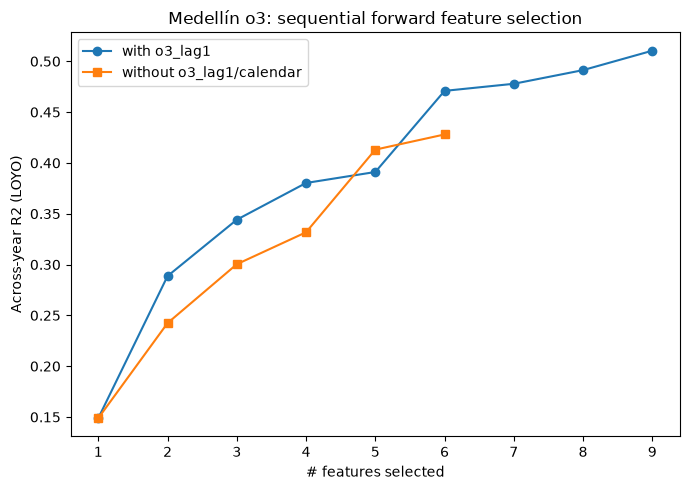

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(range(1, len(scores_with_lag) + 1), scores_with_lag, marker='o', label='with o3_lag1')
ax.plot(range(1, len(scores_no_lag) + 1), scores_no_lag, marker='s', label='without o3_lag1/calendar')
ax.set_xlabel('# features selected')
ax.set_ylabel('Across-year R2 (LOYO)')
ax.set_title('Medellín o3: sequential forward feature selection')
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'sfs_pareto_front_o3.png', dpi=150)
plt.show()


## Save selected feature sets for equation discovery

In [7]:
import json

result = {
    'selected_with_lag': selected_with_lag,
    'scores_with_lag': scores_with_lag,
    'selected_no_lag': selected_no_lag,
    'scores_no_lag': scores_no_lag,
}
out_path = DATA_DIR / "medellin_o3_feature_selection.json"
with open(out_path, 'w') as f:
    json.dump(result, f, indent=2)
print("Saved:", out_path)
print(result)


Saved: /path/to/project/Data/processed/colombia/medellin/medellin_o3_feature_selection.json
{'selected_with_lag': ['radiation_station', 'o3_lag1', 'wind_speed', 'hotspots_sector_NE_lag1', 'no_sisaire', 'no2', 'radiation_station_lag1', 'rh_10m', 'hotspots_sector_NE_lag3'], 'scores_with_lag': [0.14889570973055588, 0.28868078510214723, 0.34412645590917756, 0.38026557543573347, 0.3910606619762974, 0.47087463398272555, 0.4778473621427465, 0.4912879653540623, 0.5103957704198883], 'selected_no_lag': ['radiation_station', 'pm25_lag1', 'wind_speed', 'no_sisaire', 'no2', 'pmc_lag2'], 'scores_no_lag': [0.14889570973055588, 0.24240569806847123, 0.3003350003833476, 0.33176130808055004, 0.4130579450453937, 0.4279898606835052]}
